# 01. Baselines and RTE benchmark

Verdict: Naive baselines are more than twice as bad as RTE, so RTE raw is the benchmark to beat. MAE test: Lag 7d 3,425 MW vs RTE raw 1,439 MW (+138.0 %).

Setup: Cutoff D 12:00, forecast the 24 h of D+1, test 1 Jul 2025 to 30 Jun 2026.

## 1. Setup

At the cutoff the load is known up to D 11:00, so the last full day is D-1 (T-2 for a target day T). MAEs in MW.

In [1]:
import sys
sys.path.insert(0, "../src")

from datetime import date

import polars as pl
import matplotlib.pyplot as plt
from watt_forecast.data_preprocessing import load_dataset, save_predictions
from watt_forecast.models.baseline import naive_forecast
from watt_forecast.metrics import compute_metrics, evaluate, scorecard

TEST_START, TEST_END = date(2025, 7, 1), date(2026, 6, 30)

pl.Config.set_tbl_rows(20)
plt.rcParams["figure.figsize"] = (12, 4)

## 2. Model

- Lag 7d: same hour, same weekday, previous week.
- Lag 2d: same hour on D-1, the latest full day at the cutoff.
- RTE raw: RTE's published day-ahead forecast.

In [2]:
df = load_dataset()
df = naive_forecast(df, lag_days=7)
df = naive_forecast(df, lag_days=2)

In [3]:
def load_at(day, hour):
    return df.filter((pl.col("date") == day) & (pl.col("hour") == hour))


row = load_at(date(2026, 1, 15), 19)
assert row["pred_lag7d"].item() == load_at(date(2026, 1, 8), 19)["target"].item(), "lag 7d should copy T-7"
assert row["pred_lag2d"].item() == load_at(date(2026, 1, 13), 19)["target"].item(), "lag 2d should copy T-2"

In [4]:
forecasts = {
    "Lag 7d": "pred_lag7d",
    "Lag 2d": "pred_lag2d",
    "RTE raw": "rte_forecast_j1_mw",
}

test = df.filter(pl.col("date").is_between(TEST_START, TEST_END))
assert test.height == 365 * 24, "the test period should have 8,760 hours"
assert test["date"].min() == TEST_START and test["date"].max() == TEST_END, "wrong test period"
assert test["target"].null_count() == 0, "the target should have no nulls on the test period"

test.select(forecasts.values()).null_count()

pred_lag7d,pred_lag2d,rte_forecast_j1_mw
u32,u32,u32
1,1,1


Each forecast misses one hour out of 8,760 because of daylight saving. We just drop it from the metrics.

In [5]:
# Reference forecasts, read by 06_comparison
save_predictions(test, forecasts, "01_baseline")

## 3. Results vs benchmark

These three are the references for the other notebooks (see 06_comparison).

In [6]:
scorecard(test, forecasts)

forecast,global,evening_peak_18-20h,evening_peak_cold_days,vs_reference_(%)
str,f64,f64,f64,f64
"""Lag 7d""",3425.0,3612.0,9225.0,138.0
"""Lag 2d""",3857.0,4026.0,4346.0,168.0
"""RTE raw""",1439.0,1348.0,2307.0,0.0


What we see. Both baselines are more than twice RTE's error. Lag 7d is really bad on cold-day evening peaks (27 days) since it copies a milder week.

## 4. Where it fails

A cold week, 5 to 11 January 2026.

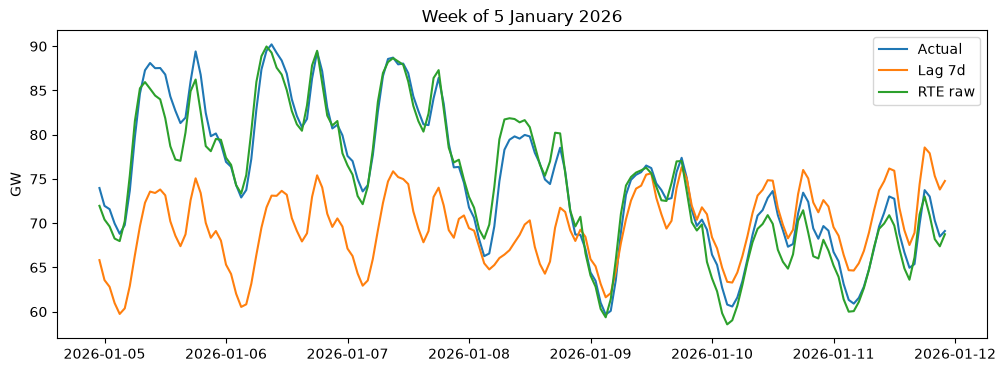

In [7]:
week = test.filter(pl.col("date").is_between(date(2026, 1, 5), date(2026, 1, 11)))

plt.plot(week["datetime_local"], week["target"] / 1000, label="Actual")
plt.plot(week["datetime_local"], week["pred_lag7d"] / 1000, label="Lag 7d")
plt.plot(week["datetime_local"], week["rte_forecast_j1_mw"] / 1000, label="RTE raw")
plt.title("Week of 5 January 2026")
plt.ylabel("GW")
plt.legend()
plt.show()

Coldest days of the test period. Lag 7d copies the milder holiday week and is off by more than 10 GW during the day, while RTE stays close. Cold days cost the most, so that's where weather data should help.

## 5. Conclusion

- Naive baselines are weak. Lag 7d breaks on cold days and weather changes, lag 2d when it copies the wrong type of day.
- Kept for next step: RTE raw as the benchmark. We'll need calendar and temperature features. The D+1 temperature is unknown at the cutoff, so using the observed one only gives an upper bound.

## Appendix

### A.1 All metrics on the test period

In [8]:
results = pl.concat(
    [evaluate(test, col).with_columns(pl.lit(name).alias("forecast")) for name, col in forecasts.items()]
)
results = results.select("forecast", "scope", "MAE", "RMSE", "MAPE", "bias")
results.with_columns(pl.col("MAE", "RMSE", "bias").round(0), pl.col("MAPE").round(2))

forecast,scope,MAE,RMSE,MAPE,bias
str,str,f64,f64,f64,f64
"""Lag 7d""","""global""",3425.0,5060.0,6.4,-53.0
"""Lag 7d""","""evening_peak_18-20h""",3612.0,5227.0,6.39,-54.0
"""Lag 7d""","""evening_peak_18-20h_cold_days""",9225.0,10910.0,12.62,-8692.0
"""Lag 2d""","""global""",3857.0,5141.0,7.78,-10.0
"""Lag 2d""","""evening_peak_18-20h""",4026.0,5036.0,7.71,-7.0
"""Lag 2d""","""evening_peak_18-20h_cold_days""",4346.0,5777.0,5.91,-2213.0
"""RTE raw""","""global""",1439.0,1783.0,2.86,-1086.0
"""RTE raw""","""evening_peak_18-20h""",1348.0,1681.0,2.49,-850.0
"""RTE raw""","""evening_peak_18-20h_cold_days""",2307.0,2773.0,3.22,-2004.0


In [9]:
n_cold_days = (
    test.group_by("date")
    .agg(pl.col("temperature_c").mean())
    .filter(pl.col("temperature_c") < 5)
    .height
)
print("Cold days (below 5 °C) in the test period:", n_cold_days)

Cold days (below 5 °C) in the test period: 27


### A.2 Error by hour of the day

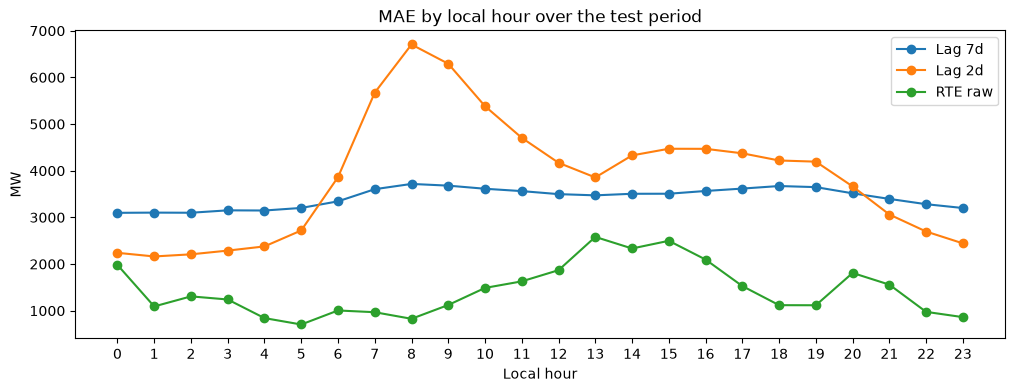

In [10]:
for name, col in forecasts.items():
    mae_by_hour = (
        test.drop_nulls(col)
        .group_by("hour")
        .agg((pl.col(col) - pl.col("target")).abs().mean().alias("mae"))
        .sort("hour")
    )
    plt.plot(mae_by_hour["hour"], mae_by_hour["mae"], marker="o", label=name)
plt.title("MAE by local hour over the test period")
plt.xlabel("Local hour")
plt.ylabel("MW")
plt.xticks(range(24))
plt.legend()
plt.show()

Lag 2d is worst in the morning, when weekdays and weekends differ the most. Lag 7d is almost flat. RTE raw goes from about 700 MW at 5:00 to about 2.5 GW from 13:00 to 15:00.

### A.3 Error by temperature

In [11]:
temp_labels = ["< 0", "0-5", "5-10", "10-15", "15-20", "20-25", "> 25"]

test = test.with_columns(
    pl.col("temperature_c").mean().over("date")
    .bin_intervals([0, 5, 10, 15, 20, 25], labels=temp_labels)
    .alias("temp_bin")
)
assert test["temp_bin"].null_count() == 0, "every test day should fall in a temperature bin"
test.group_by("temp_bin").agg(pl.col("date").n_unique().alias("n_days")).sort("temp_bin")

temp_bin,n_days
enum,u32
"""< 0""",3
"""0-5""",24
"""5-10""",83
"""10-15""",108
"""15-20""",78
"""20-25""",45
"""> 25""",24


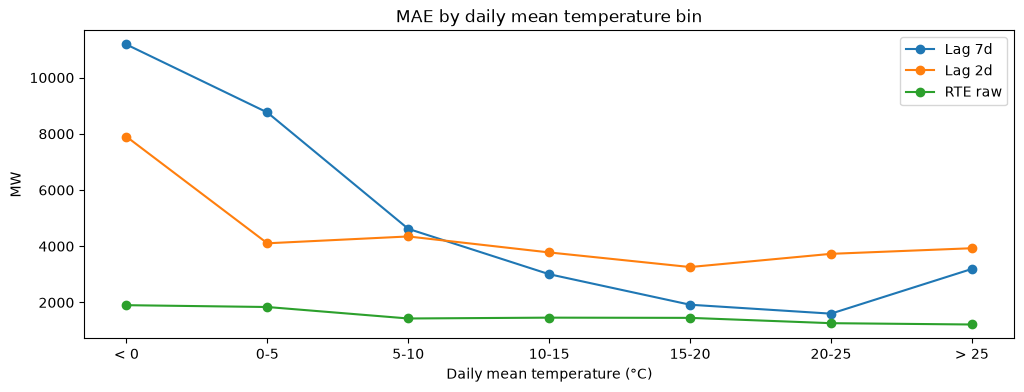

In [12]:
for name, col in forecasts.items():
    mae = [compute_metrics(test.filter(pl.col("temp_bin") == label), col)["MAE"] for label in temp_labels]
    plt.plot(temp_labels, mae, marker="o", label=name)
plt.title("MAE by daily mean temperature bin")
plt.xlabel("Daily mean temperature (°C)")
plt.ylabel("MW")
plt.legend()
plt.show()

What we see. Lag 7d is the better baseline in mild weather, but its error explodes below 5 °C and rises again above 25 °C. RTE is almost flat. Very few days in the extreme bins though (3 below 0 °C).

### A.4 Temperature change and lag 7d

In [13]:
# Temperature difference between the target day and the day copied by lag 7d
daily = (
    df.group_by("date")
    .agg(
        pl.col("temperature_c").mean(),
        (pl.col("pred_lag7d") - pl.col("target")).abs().mean().alias("mae_lag7d"),
    )
    .sort("date")
    .with_columns((pl.col("temperature_c") - pl.col("temperature_c").shift(7)).abs().alias("temp_change"))
    .filter(pl.col("date").is_between(TEST_START, TEST_END))
)

In [14]:
change_labels = ["< 2", "2-4", "4-6", ">= 6"]

daily.group_by(
    pl.col("temp_change").bin_intervals([2, 4, 6], labels=change_labels).alias("temp_change_(°C)")
).agg(
    pl.len().alias("n_days"), pl.col("mae_lag7d").mean().round(0)
).sort("temp_change_(°C)")

temp_change_(°C),n_days,mae_lag7d
enum,u32,f64
"""< 2""",133,1806.0
"""2-4""",123,3134.0
"""4-6""",47,4604.0
""">= 6""",62,6588.0


As expected, the bigger the temperature change vs the copied day, the worse lag 7d gets. At 6 °C or more the error is more than three times the stable-weather one.

### A.5 Error by day of the week

In [15]:
day_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

rows = []
for weekday, day_name in enumerate(day_names, start=1):
    day_data = test.filter(pl.col("weekday") == weekday)
    row = {"day": day_name}
    for name, col in forecasts.items():
        row[name.replace(" ", "_")] = compute_metrics(day_data, col)["MAE"]
    rows.append(row)

mae_by_weekday = pl.DataFrame(rows)
mae_by_weekday.with_columns(pl.exclude("day").round(0))

day,Lag_7d,Lag_2d,RTE_raw
str,f64,f64,f64
"""Monday""",3669.0,4500.0,1429.0
"""Tuesday""",3386.0,5999.0,1336.0
"""Wednesday""",3434.0,2132.0,1388.0
"""Thursday""",3223.0,1753.0,1423.0
"""Friday""",3340.0,2007.0,1465.0
"""Saturday""",3433.0,4894.0,1541.0
"""Sunday""",3490.0,5673.0,1492.0


What we see. Lag 2d is fine from Wednesday to Friday and fails when the copied day is of a different type (Sunday for Tuesday, Friday for Sunday). Lag 7d and RTE are about the same every day.